In [1]:
import jax.numpy as jnp
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [15]:
def analyse_convergence_results(dgp_name:str, 
                                show_uncertainty:bool=False):
    """plot the results of convergence experiments. 
    show_uncertainty uses seaborn.fill_between to show standard deviation on the plots of mean MMD"""
    
    og_exp_name='results/'+dgp_name+'.npy'
    forest_exp_name='results/'+dgp_name+'_forest.npy'
    with open(og_exp_name, 'rb') as f:
        dr_og=np.load(f)
        pi_og=np.load(f)
    try:
        with open(forest_exp_name, 'rb') as f:
            dr_f=np.load(f)
            pi_f=np.load(f)
        dr=np.concatenate((dr_og,dr_f),axis=1)
        pi=np.concatenate((pi_og,pi_f),axis=1)
    except:
        dr=dr_og
        pi=pi_og
    print(pi.shape)
    n_arr=250*np.pow(2,np.arange(dr.shape[0]))
    #print(ns)
    #n_arr=jnp.array([250,500,1000,2000,4000,8000])
    n_colors=2*dr.shape[1]
    color_list=sns.color_palette("hls", n_colors)
    if dr.shape[1] == 4:
        method_list=['logistic', 'histgbm','gbm','forest']
    elif dr.shape[1] == 2:
        method_list=['tabular mu_y', 'KRR mu_y']
    fig, axs = plt.subplots(2, 2, figsize=(12, 8))

    for j in range(dr.shape[1]):
        means_dr=np.nanmean(dr[:,j,:],axis=1)
        print(means_dr, np.count_nonzero(np.isnan(dr[:,j,:]),axis=1))
        stds_dr=np.nanstd(dr[:,j,:],axis=1)
        dr_color=color_list[j]
        dr_label=method_list[j]+ ' one-step'

        axs[0,0].plot(n_arr,means_dr, color=dr_color, label=dr_label)
        axs[0,1].plot(n_arr,stds_dr, color=dr_color, label=dr_label)
        axs[1,0].plot(n_arr,np.sqrt(n_arr)*means_dr, color=dr_color, label=dr_label)
        axs[1,1].plot(n_arr,np.sqrt(n_arr)*stds_dr, color=dr_color, label=dr_label)
        
        means_pi=np.nanmean(pi[:,j,:],axis=1)
        print(means_pi,np.count_nonzero(np.isnan(pi[:,j,:]),axis=1))
        stds_pi=np.nanstd(pi[:,j,:],axis=1)
        pi_color=color_list[j+dr.shape[1]]
        pi_label=method_list[j]+ ' plug-in'
        axs[0,0].plot(n_arr,means_pi, color=pi_color, label=pi_label)
        axs[0,1].plot(n_arr,stds_pi, color=pi_color, label=pi_label)
        axs[1,0].plot(n_arr,np.sqrt(n_arr)*means_pi, color=pi_color, label=pi_label)
        axs[1,1].plot(n_arr,np.sqrt(n_arr)*stds_pi, color=pi_color, label=pi_label)

        if show_uncertainty:
            axs[0,0].fill_between(n_arr, means_dr-stds_dr, means_dr+stds_dr ,alpha=0.3, facecolor=dr_color)
            axs[1,0].fill_between(n_arr, jnp.sqrt(n_arr)*(means_dr-stds_dr), jnp.sqrt(n_arr)*(means_dr+stds_dr) ,alpha=0.3, facecolor=dr_color)
            axs[1,0].fill_between(n_arr, jnp.sqrt(n_arr)*(means_pi-stds_pi), jnp.sqrt(n_arr)*(means_pi+stds_pi) ,alpha=0.3, facecolor=pi_color)
            axs[0,0].fill_between(n_arr, means_pi-stds_pi, means_pi+stds_pi ,alpha=0.3, facecolor=pi_color)

    """
    means_pi=jnp.nanmean(pi[:,0,:],axis=1)
    print(means_pi)
    stds_pi=jnp.nanstd(pi[:,0,:],axis=1)
    pi_color='y'
    pi_label=method_list[0]+ ' plug-in'
    axs[0,0].plot(n_arr,means_pi, color=pi_color, label=pi_label)
    axs[0,1].plot(n_arr,stds_pi, color=pi_color, label=pi_label)
    axs[1,0].plot(n_arr,jnp.sqrt(n_arr)*means_pi, color=pi_color, label=pi_label)
    axs[1,1].plot(n_arr,jnp.sqrt(n_arr)*stds_pi, color=pi_color, label=pi_label)
    """


    axs[0,0].set_xlabel("n")
    axs[0,0].set_ylabel("mean")
    #axs[0,0].set_yscale('log')
    #axs[0,0].set_ylim(bottom=2.4e-1,top=2.6e-1)
    axs[0,0].legend()
    axs[0,1].set_xlabel("n")
    axs[0,1].set_ylabel("standard deviation")
    #axs[0,1].set_yscale('log')
    #axs[0,1].set_ylim(top=1e-1)
    axs[0,1].legend()
    axs[1,0].set_xlabel("n")
    axs[1,0].set_ylabel("$\sqrt{n}$-mean")
    #axs[1,0].set_yscale('log')
    #axs[1,0].set_ylim(top=30,bottom=0)
    axs[1,0].legend()
    axs[1,1].set_xlabel("n")
    axs[1,1].set_ylabel("$\sqrt{n}$-standard deviation")
    #axs[1,1].set_yscale('log')
    #axs[1,1].set_ylim(top=2)
    axs[1,1].legend()

    path='figures/'+dgp_name+'_results.png'
    plt.savefig(path)
    plt.show()
    plt.close()
    

<>:84: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:89: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:84: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:89: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
/var/folders/ym/ygcsp08s7fgc4wgspd4lk4lw0000gn/T/ipykernel_78383/1842945999.py:84: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
  axs[1,0].set_ylabel("$\sqrt{n}$-mean")
/var/folders/ym/ygcsp08s7fgc4wgspd4lk4lw0000gn/T/ipykernel_78383/1842945999.py:89: SyntaxWarning: "\s" is an inva

In [16]:
def result_distribution(dgp_name,n_index,method_index):
    og_exp_name=dgp_name+'.npy'
    forest_exp_name=dgp_name+'_forest.npy'
    with open(og_exp_name, 'rb') as f:
        dr_og=jnp.load(f)
        pi_og=jnp.load(f)
    try:
        with open(forest_exp_name, 'rb') as f:
            dr_f=jnp.load(f)
            pi_f=jnp.load(f)
        dr=jnp.concatenate((dr_og,dr_f),axis=1)
        pi=jnp.concatenate((pi_og,pi_f),axis=1)
    except:
        dr=dr_og
        pi=pi_og
    n_arr=jnp.array([250,500,1000,2000,4000,8000])
    color_list=['b','g','r','c','m','y']
    method_list=['logistic', 'histgbm','gbm','forest']

    data=dr[n_index,method_index,:]
    print(f"stats:\nmean: {jnp.nanmean(data)}\nmedian: {jnp.nanmedian(data)}\nmax: {jnp.max(data)}\nmin: {jnp.min(data)}")
    sns.histplot(data)
    plt.show()
    plt.close()
    

(6, 2, 200)
[0.25057465 0.24821563 0.24706583 0.24584442 0.2439627  0.24408802] [5 0 0 0 0 0]
[0.25057465 0.24821563 0.24706583 0.24584442 0.2439627  0.24408802] [5 0 0 0 0 0]
[0.25319755 0.25000128 0.24748549 0.24594681 0.24394655 0.24603939] [5 0 0 0 0 0]
[0.25319755 0.25000128 0.24748549 0.24594681 0.24394655 0.24593474] [5 0 0 0 0 0]


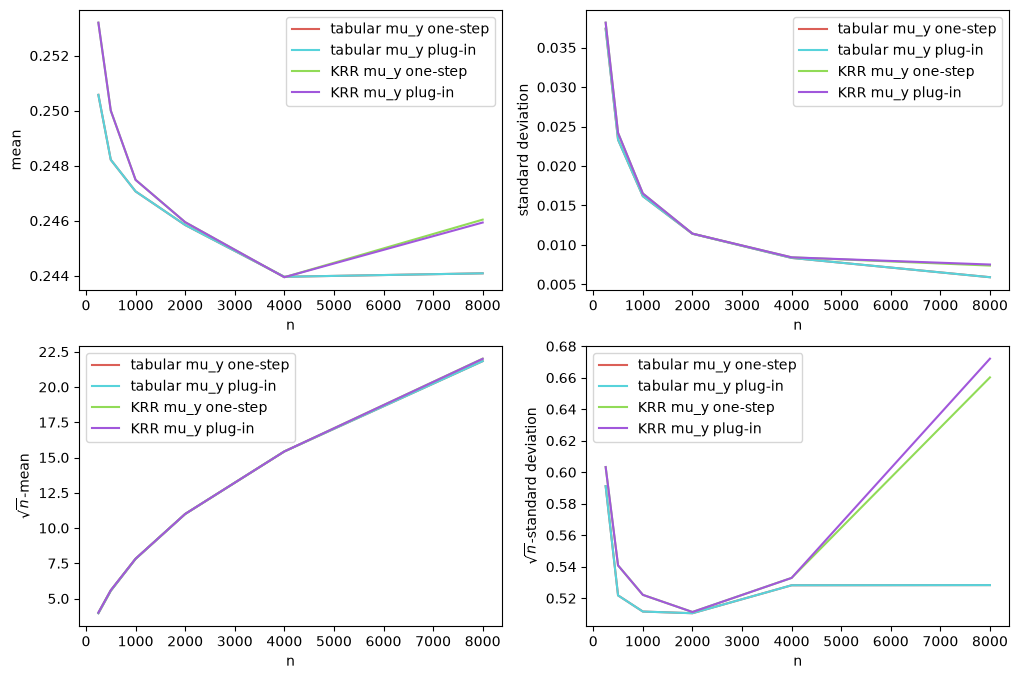

In [17]:
analyse_convergence_results('binary_tabular_v2')

(6, 2, 200)
[0.25057465 0.24821563 0.24706583 0.24584442 0.2439627  0.24408802] [5 0 0 0 0 0]
[0.25057465 0.24821563 0.24706583 0.24584442 0.2439627  0.24408802] [5 0 0 0 0 0]
[0.25319755 0.25000128 0.24748549 0.24594681 0.24394655 0.24603939] [5 0 0 0 0 0]
[0.25319755 0.25000128 0.24748549 0.24594681 0.24394655 0.24593474] [5 0 0 0 0 0]


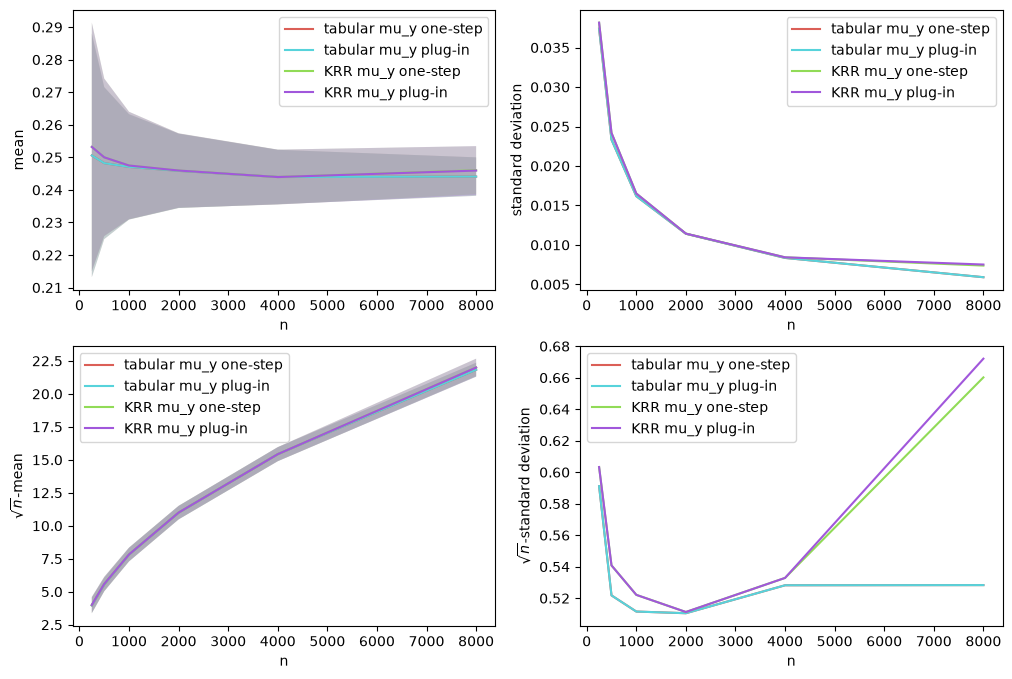

In [18]:
analyse_convergence_results('binary_tabular_v2',True)

(8, 2, 50)
[0.24415357 0.24789196 0.24655014 0.24693769 0.24392718 0.24501175
 0.24547514 0.2442928 ] [2 0 0 0 0 0 0 0]
[0.24415357 0.24789196 0.24655014 0.24693769 0.24392718 0.24501175
 0.24547514 0.2442928 ] [2 0 0 0 0 0 0 0]
[0.24786454 0.24923053 0.24685429 0.2470192  0.2440272  0.24663073
 0.25692317 0.2679907 ] [2 0 0 0 0 0 0 0]
[0.24786454 0.24923053 0.24685429 0.2470192  0.2440272  0.24663073
 0.25692317 0.2661002 ] [2 0 0 0 0 0 0 0]


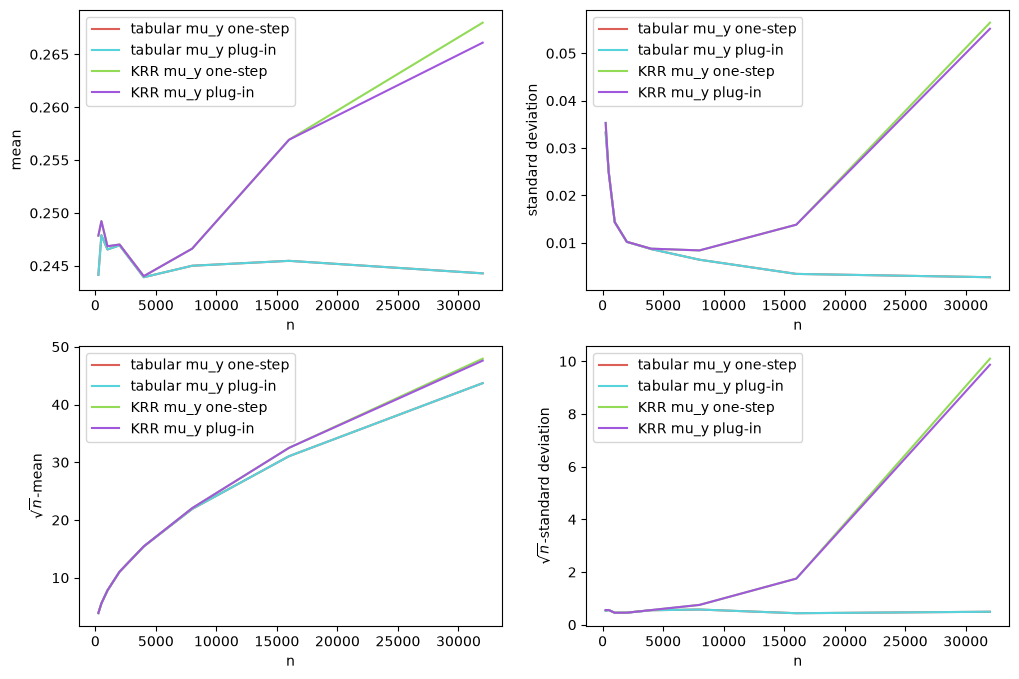

In [19]:
analyse_convergence_results('binary_tabular')

(8, 2, 50)
[0.24415357 0.24789196 0.24655014 0.24693769 0.24392718 0.24501175
 0.24547514 0.2442928 ] [2 0 0 0 0 0 0 0]
[0.24415357 0.24789196 0.24655014 0.24693769 0.24392718 0.24501175
 0.24547514 0.2442928 ] [2 0 0 0 0 0 0 0]
[0.24786454 0.24923053 0.24685429 0.2470192  0.2440272  0.24663073
 0.25692317 0.2679907 ] [2 0 0 0 0 0 0 0]
[0.24786454 0.24923053 0.24685429 0.2470192  0.2440272  0.24663073
 0.25692317 0.2661002 ] [2 0 0 0 0 0 0 0]


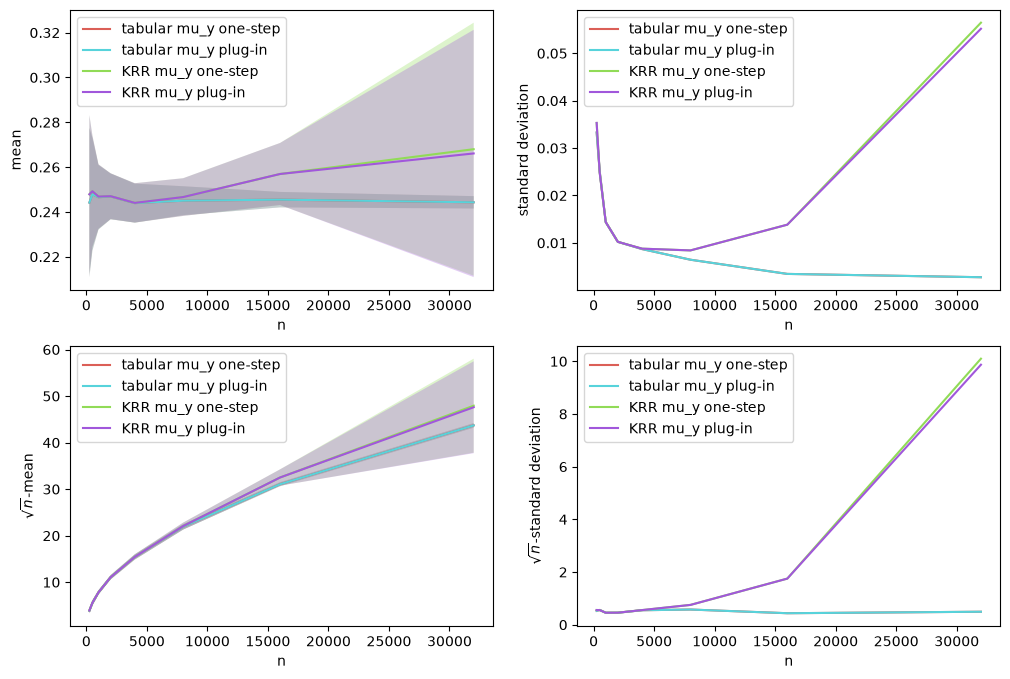

In [20]:
analyse_convergence_results('binary_tabular',True)